# Notebook 83: Raw vs Standardized PCA of Bottom-Layer DO
### Covariance-matrix PCA (`raw`) vs correlation-matrix PCA (`standardized`) in `step4_PCA_analysis`

---

## 1. Background

Step 4 runs PCA/EOF analysis on the interannual summer bottom-layer DO matrix. Since the `pca_mode` parameter was added to `step4_parameter.csv`, it runs in two modes:

| Mode | Input to `PCA()` | Matrix decomposed | What it emphasises |
|---|---|---|---|
| `raw` | $X_{ij} - \bar X_j$ (column-centred only, done internally by sklearn) | Covariance matrix $C = \frac{1}{n-1}X_c^\top X_c$ | Stations with **large absolute DO swings (mg/L)** dominate the leading modes |
| `standardized` | $Z_{ij} = (X_{ij} - \bar X_j)/s_j$ via `StandardScaler` | Correlation matrix $R = \frac{1}{n-1}Z^\top Z$ | Every station has **unit variance**, so modes reflect the **coherence** of patterns, not amplitude |

Here $X$ is **years × stations** (rows are samples, columns are variables), exactly as in `process01` / `process11` (`pca_input_data = interpolated_do_df.T`).

**Why it matters.** Covariance-matrix PCA maximises explained variance in mg/L². If a handful of stations (e.g. hypoxic inner-bay stations) have much larger interannual variance than the rest, EOF1 can collapse onto those stations and the PC1 time series largely becomes *their* time series. Correlation-matrix PCA removes that amplitude weighting, so a station with a small but highly coherent signal counts as much as a noisy, high-variance one.

**Reading explained variance.** In `raw` mode the % is a share of total variance (mg/L²). In `standardized` mode it is a share of the number of stations (trace of $R$ = $p$). These percentages are **not on the same scale** and should be compared with care: what matters most is whether the *patterns* (EOFs) and *time series* (PCs) agree.

**Comparison metrics used below**
- **Tucker congruence** between EOFs: $\phi = \frac{\sum_j a_j b_j}{\sqrt{\sum a_j^2 \sum b_j^2}}$ (cosine similarity; $|\phi| > 0.95$ ≈ equal patterns, $0.85$–$0.95$ ≈ fair similarity, $< 0.85$ ≈ different).
- **Pearson r** between PC score time series.
- **Coefficient of variation (CV) of station std**: how unequal the station variances are. When CV → 0, both modes give the same answer, so a high CV predicts divergence.

PCA signs are arbitrary, so every standardized component is sign-aligned to its raw counterpart before comparing.

In [1]:
# --- 1. Imports & Environment Setup ---
import sys
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import yaml
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Resolve project root (sits 1 level above step0_sandbox)
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths
from utils.mapping_config import MappingConfig
from utils.data_loader import load_and_process_data

MappingConfig.apply_global_plot_styles()
warnings.filterwarnings('ignore')
print(f"Project root resolved to: {project_root}")

Project root resolved to: /home/reyha/SIS_Analysis_WSL


## 2. Output Directory & Parameters
- Outputs go to `figures/step0_sandbox/83_raw_vs_standardized_pca_comparison/` (wiped and recreated on each run).
- Parameters are read from `83_raw_vs_standardized_pca_comparison_parameters.csv` next to this notebook. If it is missing, defaults are written. `season`/`layer` default to the values in `step1_parameter.csv`, and `divisions` to `step3_parameter.csv`, the same sources `process01`/`main.py` use.

In [2]:
# --- 2. Output Directory & Parameters ---
notebook_name = "83_raw_vs_standardized_pca_comparison"
output_dir = ProjectPaths.FIGURES_DIR / "step0_sandbox" / notebook_name
if output_dir.exists():
    shutil.rmtree(output_dir, ignore_errors=True)
output_dir.mkdir(parents=True, exist_ok=True)

def read_param_csv(path):
    if not path.exists():
        return {}
    df = pd.read_csv(path)
    return dict(zip(df['parameter_name'], df['value']))

step1_params = read_param_csv(ProjectPaths.PROJECT_ROOT / "step1_data_processing_cleaning" / "step1_parameter.csv")
step3_params = read_param_csv(ProjectPaths.PROJECT_ROOT / "step3_decorrelation_scale_analysis" / "step3_parameter.csv")

param_file = Path(f"{notebook_name}_parameters.csv").resolve()
if not param_file.exists():
    pd.DataFrame({
        'parameter_name': ['season', 'layer', 'divisions', 'n_components', 'top_n_stations', 'map_divisions'],
        'value': [
            step1_params.get('season', 'Summer'),
            step1_params.get('layer', 'bottom'),
            step3_params.get('divisions', 'Seto Inland Sea, Tokyo Bay, Ise Mikawa Bay, Osaka Bay'),
            10,
            10,
            'Tokyo Bay; Ise Mikawa Bay; Osaka Bay',
        ],
        'type': ['str', 'str', 'str', 'int', 'int', 'str'],
        'description': [
            'Season subset (as step1)',
            'Depth layer subset (as step1)',
            'Comma-separated divisions (as step3); Seto Inland Sea expands to its sub-basins like step4 main.py',
            'Maximum number of PCA components',
            'Number of top-|loading| stations compared between modes',
            'Semicolon-separated divisions for which per-bay EOF maps are drawn',
        ],
    }).to_csv(param_file, index=False)
    print(f"Wrote default parameters to {param_file}")

PARAMS = read_param_csv(param_file)
SEASON = PARAMS['season']
LAYER = PARAMS['layer']
DIVISIONS = [d.strip() for d in str(PARAMS['divisions']).split(',')]
N_COMPONENTS = int(PARAMS['n_components'])
TOP_N = int(PARAMS['top_n_stations'])
MAP_DIVISIONS = [d.strip() for d in str(PARAMS['map_divisions']).split(';')]
MODES = ['raw', 'standardized']

try:
    with open(ProjectPaths.PROJECT_ROOT / 'params.yaml') as f:
        TARGET_REGION = yaml.safe_load(f)['mapping']['target_region']
except Exception:
    TARGET_REGION = 'Seto Inland Sea'

display(pd.read_csv(param_file))
print(f"Output directory: {output_dir}")

,parameter_name,value,type,description
0,season,Summer,str,Season subset (as step1)
1,layer,bottom,str,Depth layer subset (as step1)
2,divisions,"Seto Inland Sea, Tokyo Bay, Ise Mikawa Bay, Os...",str,Comma-separated divisions (as step3); Seto Inl...
3,n_components,10,int,Maximum number of PCA components
4,top_n_stations,10,int,Number of top-|loading| stations compared betw...
5,map_divisions,Tokyo Bay; Ise Mikawa Bay; Osaka Bay,str,Semicolon-separated divisions for which per-ba...


Output directory: /home/reyha/SIS_Analysis_WSL/figures/step0_sandbox/83_raw_vs_standardized_pca_comparison


## 3. Data Loading
The same inputs as the pipeline:
- **Global** (`process01`): `interpolated_do_df.csv` from the season/layer subset directory.
- **Per bay** (`process11`): `yearly_do_df.csv`, `dist_matrix_km.csv`, station metadata from `load_and_process_data()`, and the per-bay decorrelation scales from step 3.

Missing inputs are reported and the dependent section is skipped instead of raising.

In [3]:
# --- 3. Load Datasets with Existence Checks ---
subset_dir = ProjectPaths.get_subset_dir(SEASON, LAYER)
inputs = {
    'interpolated_do': subset_dir / "interpolated_do_df.csv",
    'yearly_do': subset_dir / "yearly_do_df.csv",
    'dist_matrix': ProjectPaths.PROCESSED_DATA_DIR / "dist_matrix_km.csv",
}
missing = [k for k, p in inputs.items() if not p.exists()]
for k in missing:
    print(f"WARNING: missing input '{k}': {inputs[k]}")

interpolated_do_df = yearly_do_df = dist_matrix_km = None
if 'interpolated_do' not in missing:
    interpolated_do_df = pd.read_csv(inputs['interpolated_do'], index_col=0)
    interpolated_do_df.index = interpolated_do_df.index.astype(str).str.zfill(8)
    print(f"interpolated_do_df: {interpolated_do_df.shape[0]} stations x {interpolated_do_df.shape[1]} years")
if 'yearly_do' not in missing:
    yearly_do_df = pd.read_csv(inputs['yearly_do'], index_col=0)
    yearly_do_df.index = yearly_do_df.index.astype(str).str.zfill(8)
    print(f"yearly_do_df: {yearly_do_df.shape[0]} stations x {yearly_do_df.shape[1]} years")
if 'dist_matrix' not in missing:
    dist_matrix_km = pd.read_csv(inputs['dist_matrix'], index_col=0)
    dist_matrix_km.index = dist_matrix_km.index.astype(str).str.zfill(8)
    dist_matrix_km.columns = dist_matrix_km.columns.astype(str).str.zfill(8)

merged_gdf = load_and_process_data(force_reload=False)
station_coords = merged_gdf[['zettaicode', 'latitude', 'longitude']].drop_duplicates('zettaicode').copy()
station_coords['Station_ID'] = station_coords['zettaicode'].astype(str).str.zfill(8)
station_coords = station_coords.set_index('Station_ID')[['latitude', 'longitude']]
print(f"Station coordinates: {len(station_coords)} stations")

interpolated_do_df: 124 stations x 41 years
yearly_do_df: 185 stations x 43 years
Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...


Station coordinates: 188 stations


## 4. Pipeline Logic (reproduced)
The pipeline scripts cannot be imported: they parse CLI args and `rmtree` their output folders at import time. The functions below are therefore copied from the pipeline:
- `gaussian_weight` / `interpolate_missing_do`: verbatim from `process11_calculate_pca_explained_variance_per_bay_raw.py`.
- `run_pca`: the PCA block shared by `process01` and `process11`: temporal-mean NaN fill, transpose to years × stations, `StandardScaler` in `standardized` mode, then `PCA(n_components)`.
- `load_division_matrix`: the per-bay station selection and interpolation from `process11.main()`.

In [4]:
# --- 4a. Interpolation (verbatim from process11) ---
def gaussian_weight(distance, scale):
    return np.exp(-(distance**2) / (2 * scale**2))

def interpolate_missing_do(yearly_do_df, decorrelation_df, dist_matrix, weighting_func='gaussian', min_weight=0.01):
    search_radius_factor = 2.0
    interpolated_df = yearly_do_df.copy()
    common_stations = list(set(yearly_do_df.index) & set(decorrelation_df.index) & set(dist_matrix.index))

    for year in yearly_do_df.columns:
        for station in common_stations:
            if not pd.isna(yearly_do_df.loc[station, year]):
                continue
            scale = decorrelation_df.loc[station, 'Decorrelation_Scale_km']
            if pd.isna(scale) or scale <= 0:
                continue

            search_radius = search_radius_factor * scale
            valid_stations = yearly_do_df.index[~pd.isna(yearly_do_df[year])].tolist()
            neighbors = [s for s in valid_stations if s in common_stations and s != station]
            if len(neighbors) == 0:
                continue

            distances = dist_matrix.loc[station, neighbors]
            within_radius = distances[distances <= search_radius]
            if len(within_radius) == 0:
                continue

            neighbors_in_radius = within_radius.index.tolist()
            dist_vals = dist_matrix.loc[station, neighbors_in_radius].values
            do_vals = yearly_do_df.loc[neighbors_in_radius, year].values
            weight_vals = gaussian_weight(dist_vals, scale)
            valid_mask = weight_vals > min_weight
            if valid_mask.sum() == 0:
                continue

            interpolated_df.loc[station, year] = (do_vals[valid_mask] * weight_vals[valid_mask]).sum() / weight_vals[valid_mask].sum()

    mean_fallback = interpolated_df.mean(axis=1)
    for col in interpolated_df.columns:
        interpolated_df[col] = interpolated_df[col].fillna(mean_fallback)

    return interpolated_df

In [5]:
# --- 4b. PCA (process01 / process11 logic for both modes) ---
def run_pca(do_df, mode, n_components=N_COMPONENTS):
    # do_df: stations x years. Returns dict with model, scores (years x PCs), eofs (stations x PCs), variance %
    do_df = do_df.fillna(do_df.mean(axis=0))
    pca_input_data = do_df.T
    if mode == 'standardized':
        # z-score each station over time so PCA decomposes the correlation matrix
        pca_input_data = StandardScaler().fit_transform(pca_input_data)
    n = min(n_components, do_df.shape[0], do_df.shape[1])
    model = PCA(n_components=n)
    scores = model.fit_transform(pca_input_data)
    pcs = [f'PC{i+1}' for i in range(n)]
    return {
        'model': model,
        'filled': do_df,
        'scores': pd.DataFrame(scores, index=do_df.columns.astype(int), columns=pcs),
        'eofs': pd.DataFrame(model.components_.T, index=do_df.index, columns=[p.replace('PC', 'EOF') for p in pcs]),
        'var_pct': pd.Series(model.explained_variance_ratio_ * 100, index=pcs),
    }

def align_signs(ref, other, k=2):
    # Flip sign of other's first k components so their EOFs point the same way as ref's
    for i in range(1, k + 1):
        if np.dot(ref['eofs'][f'EOF{i}'], other['eofs'][f'EOF{i}']) < 0:
            other['eofs'][f'EOF{i}'] *= -1
            other['scores'][f'PC{i}'] *= -1
    return other

def congruence(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return float(np.dot(a, b) / np.sqrt(np.dot(a, a) * np.dot(b, b)))

def compare_modes(res_raw, res_std, k=2):
    station_std = res_raw['filled'].std(axis=1)
    row = {'n_stations': len(station_std), 'n_years': res_raw['filled'].shape[1],
           'station_std_cv': station_std.std() / station_std.mean()}
    for i in range(1, k + 1):
        row[f'PC{i}_var_raw'] = res_raw['var_pct'][f'PC{i}']
        row[f'PC{i}_var_std'] = res_std['var_pct'][f'PC{i}']
        row[f'EOF{i}_congruence'] = congruence(res_raw['eofs'][f'EOF{i}'], res_std['eofs'][f'EOF{i}'])
        row[f'PC{i}_score_r'] = res_raw['scores'][f'PC{i}'].corr(res_std['scores'][f'PC{i}'])
    top_raw = set(res_raw['eofs']['EOF1'].abs().nlargest(TOP_N).index)
    top_std = set(res_std['eofs']['EOF1'].abs().nlargest(TOP_N).index)
    row[f'EOF1_top{TOP_N}_overlap'] = len(top_raw & top_std)
    return row

In [6]:
# --- 4c. Per-division input matrix (process11.main logic) ---
DECORR_DIR = ProjectPaths.PROCESSED_DATA_DIR / "step3_decorrelation_scale_analysis" / "process11_calculate_decorrelation_scale_per_bay"

def load_division_matrix(division):
    db_division = 'Ise Bay' if division in ['Ise Mikawa Bay', 'Ise-Mikawa Bay'] else division
    division_stations = merged_gdf[
        (merged_gdf['watermass_name'] == db_division) | (merged_gdf['division'] == db_division)
    ]['zettaicode'].unique()
    division_stations_str = [str(st).zfill(8) for st in division_stations]
    yearly_do_df_div = yearly_do_df[yearly_do_df.index.isin(division_stations_str)].copy()
    if yearly_do_df_div.empty:
        print(f"  {division}: no stations in yearly_do_df, skipped")
        return None

    div_slug = division.replace(' ', '_').lower()
    decorrelation_file = DECORR_DIR / div_slug / f"{div_slug}_decorrelation_scale.csv"
    if division == 'Ise Bay' and not decorrelation_file.exists():
        div_slug = 'ise_mikawa_bay'
        decorrelation_file = DECORR_DIR / div_slug / f"{div_slug}_decorrelation_scale.csv"
    if not decorrelation_file.exists():
        print(f"  {division}: decorrelation scale file not found, skipped")
        return None

    decorrelation_df = pd.read_csv(decorrelation_file, index_col='Station_ID')
    decorrelation_df.index = decorrelation_df.index.astype(str).str.zfill(8)
    interpolated = interpolate_missing_do(yearly_do_df_div, decorrelation_df, dist_matrix_km)
    interpolated = interpolated.fillna(interpolated.mean(axis=0))
    if interpolated.empty or len(interpolated) < 2:
        print(f"  {division}: insufficient interpolated data, skipped")
        return None
    return interpolated

## 5. Global Comparison (combined regions, as `process01`–`03`)

In [7]:
# --- 5a. Run both modes on the global matrix ---
glob = {}
if interpolated_do_df is not None:
    glob['raw'] = run_pca(interpolated_do_df, 'raw')
    glob['standardized'] = align_signs(glob['raw'], run_pca(interpolated_do_df, 'standardized'))
    global_summary = pd.Series(compare_modes(glob['raw'], glob['standardized']), name='Global')
    display(global_summary.to_frame().round(3))
else:
    print("Global input missing: section 5 skipped.")

,Global
n_stations,124.000
n_years,41.000
station_std_cv,0.446
PC1_var_raw,15.607
PC1_var_std,14.078
EOF1_congruence,0.798
PC1_score_r,0.888
PC2_var_raw,8.857
PC2_var_std,9.742
EOF2_congruence,0.527


### 5.1 Explained variance (scree)
Remember that the two percentages are relative to different totals (mg/L² vs number of stations). A flatter standardized scree means variance is spread more evenly once the high-amplitude stations stop dominating.

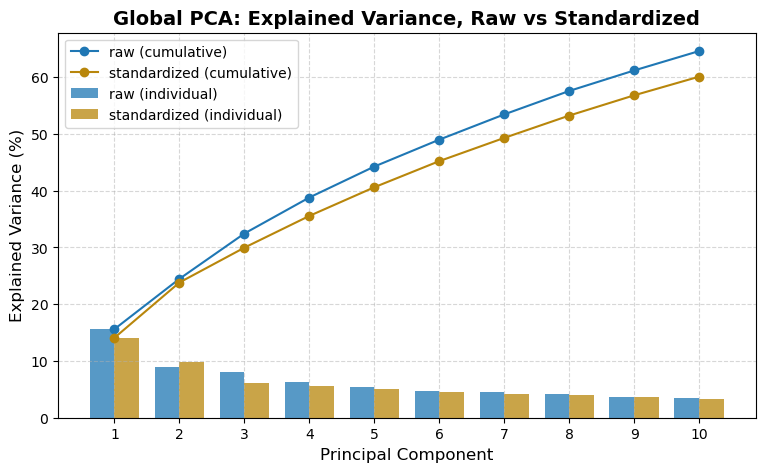

,raw,standardized
PC1,15.61,14.08
PC2,8.86,9.74
PC3,7.99,6.14
PC4,6.35,5.59
PC5,5.45,5.05
PC6,4.74,4.60
PC7,4.45,4.09
PC8,4.13,3.93
PC9,3.61,3.57
PC10,3.42,3.29


In [8]:
# --- 5b. Scree comparison ---
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(1, len(glob['raw']['var_pct']) + 1)
w = 0.38
colors = {'raw': 'tab:blue', 'standardized': 'darkgoldenrod'}
for off, mode in [(-w/2, 'raw'), (w/2, 'standardized')]:
    v = glob[mode]['var_pct'].values
    ax.bar(x + off, v, width=w, color=colors[mode], alpha=0.75, label=f'{mode} (individual)')
    ax.plot(x, np.cumsum(v), marker='o', color=colors[mode], label=f'{mode} (cumulative)')
ax.set_xticks(x)
ax.set_xlabel('Principal Component')
ax.set_ylabel('Explained Variance (%)')
ax.set_title('Global PCA: Explained Variance, Raw vs Standardized')
ax.legend(fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5)
fig.savefig(output_dir / 'global_scree_raw_vs_standardized.png', bbox_inches='tight', dpi=300)
plt.show()

display(pd.DataFrame({m: glob[m]['var_pct'] for m in MODES}).round(2))

### 5.2 Why the modes differ: unequal station variance
In `raw` mode a station's |EOF1| loading tends to grow with its temporal standard deviation. Standardization removes that dependence. The scatter below shows how strongly the raw EOF1 is driven by amplitude.

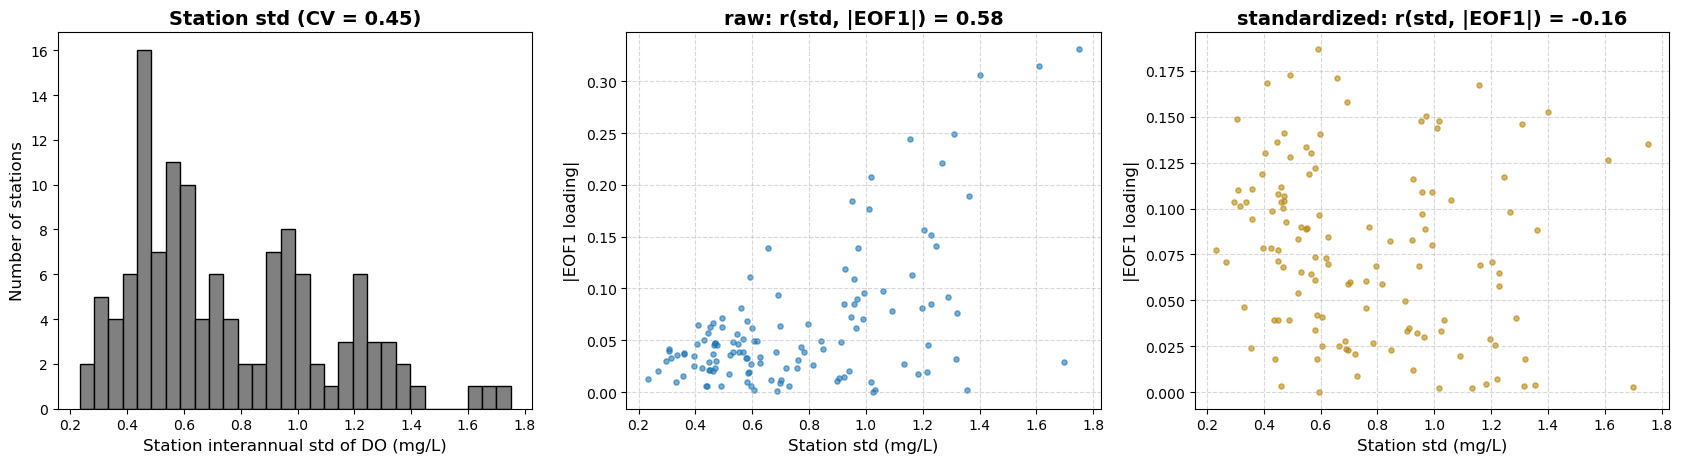

In [9]:
# --- 5c. Station variance diagnostics ---
station_std = glob['raw']['filled'].std(axis=1)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].hist(station_std, bins=30, color='grey', edgecolor='k')
axes[0].set_xlabel('Station interannual std of DO (mg/L)')
axes[0].set_ylabel('Number of stations')
axes[0].set_title(f'Station std (CV = {station_std.std()/station_std.mean():.2f})')
for ax, mode in zip(axes[1:], MODES):
    load = glob[mode]['eofs']['EOF1'].abs()
    r = np.corrcoef(station_std, load)[0, 1]
    ax.scatter(station_std, load, s=14, alpha=0.6, color=colors[mode])
    ax.set_xlabel('Station std (mg/L)')
    ax.set_ylabel('|EOF1 loading|')
    ax.set_title(f'{mode}: r(std, |EOF1|) = {r:.2f}')
    ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
fig.savefig(output_dir / 'global_station_std_vs_eof1.png', bbox_inches='tight', dpi=300)
plt.show()

### 5.3 Pattern and time-series agreement
Left: EOF loadings, raw vs standardized (after sign alignment), with Tucker congruence φ. Right: PC scores, z-scored so the different units are comparable, with Pearson r.

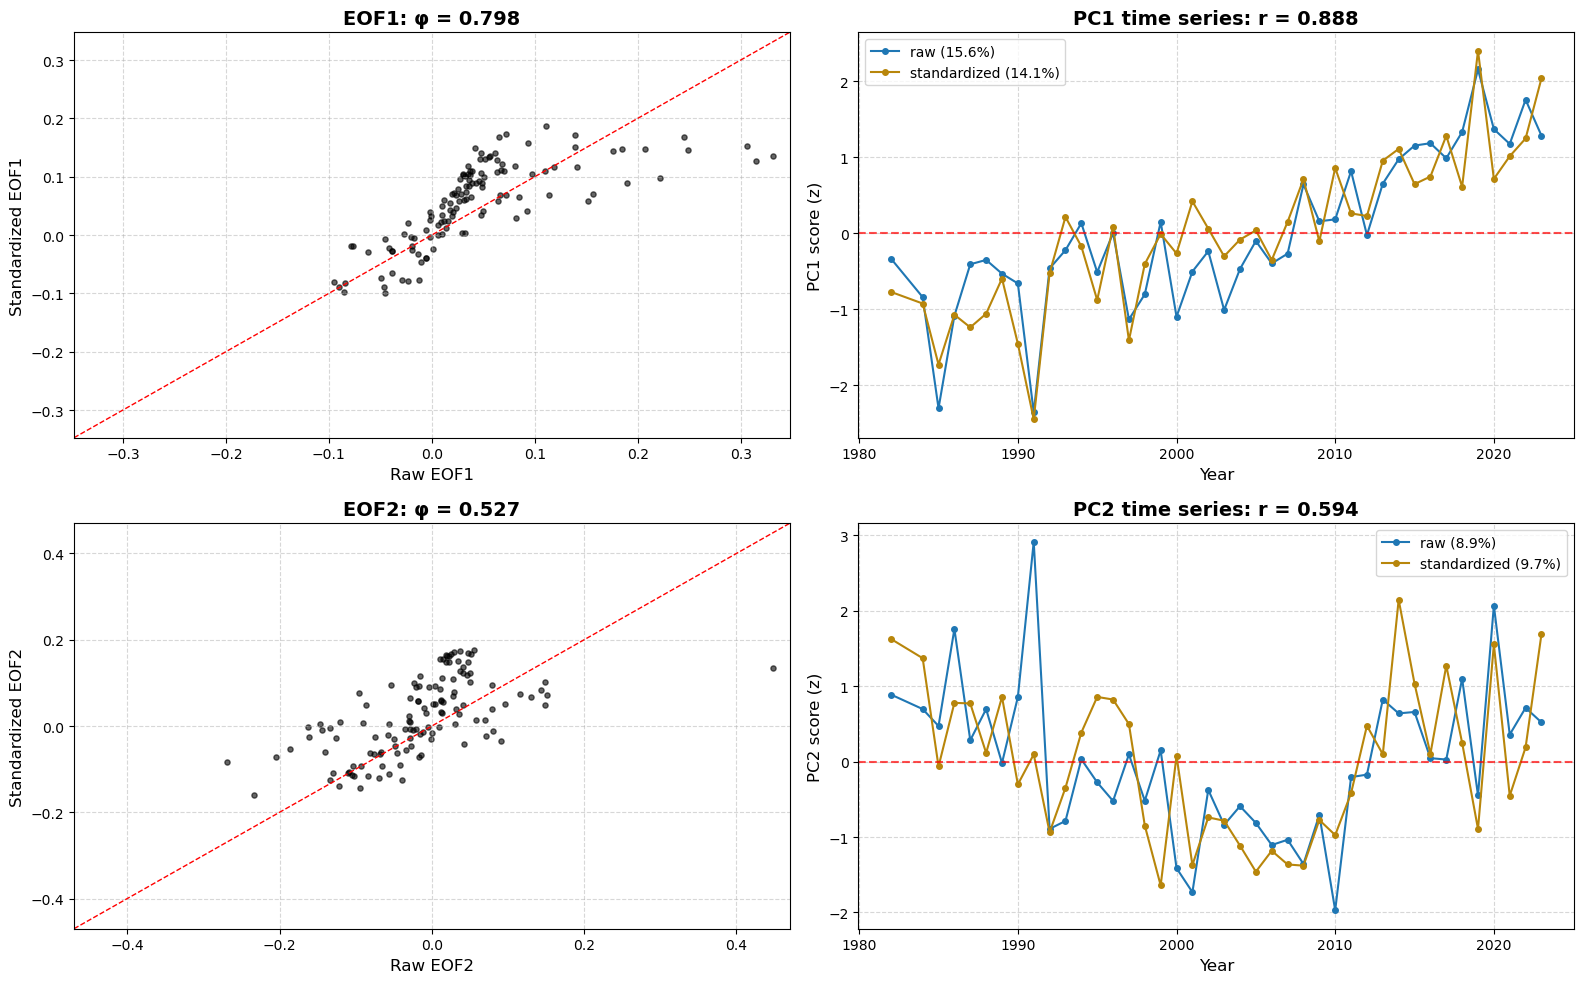

In [10]:
# --- 5d. EOF loading scatter and PC time series ---
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for i, pc in enumerate(['1', '2']):
    a, b = glob['raw']['eofs'][f'EOF{pc}'], glob['standardized']['eofs'][f'EOF{pc}']
    ax = axes[i, 0]
    ax.scatter(a, b, s=14, alpha=0.6, color='k')
    lim = max(a.abs().max(), b.abs().max()) * 1.05
    ax.plot([-lim, lim], [-lim, lim], 'r--', lw=1)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_xlabel(f'Raw EOF{pc}')
    ax.set_ylabel(f'Standardized EOF{pc}')
    ax.set_title(f'EOF{pc}: φ = {congruence(a, b):.3f}')
    ax.grid(True, linestyle='--', alpha=0.5)

    ax = axes[i, 1]
    for mode in MODES:
        s = glob[mode]['scores'][f'PC{pc}']
        ax.plot(s.index, (s - s.mean()) / s.std(), marker='o', ms=4, color=colors[mode],
                label=f"{mode} ({glob[mode]['var_pct'][f'PC{pc}']:.1f}%)")
    r = glob['raw']['scores'][f'PC{pc}'].corr(glob['standardized']['scores'][f'PC{pc}'])
    ax.axhline(0, color='red', ls='--', alpha=0.7)
    ax.set_xlabel('Year')
    ax.set_ylabel(f'PC{pc} score (z)')
    ax.set_title(f'PC{pc} time series: r = {r:.3f}')
    ax.legend(fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
fig.savefig(output_dir / 'global_eof_scatter_and_pc_timeseries.png', bbox_inches='tight', dpi=300)
plt.show()

### 5.4 EOF maps side by side
The map styling follows `process03_plot_pca_eof_map_raw.plot_eof_map` (dynamic extent, land boundaries, `coolwarm`, marker size ∝ |loading|). Each panel has its own symmetric colour scale: standardized loadings are spread across more stations, so absolute values are not comparable between panels.

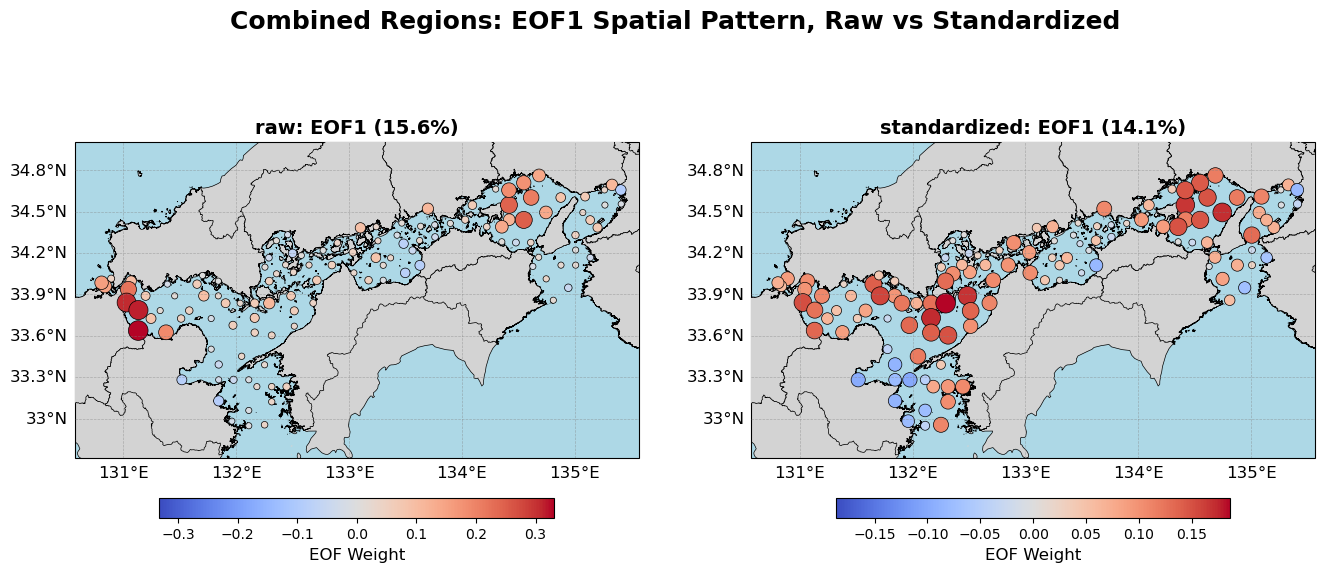

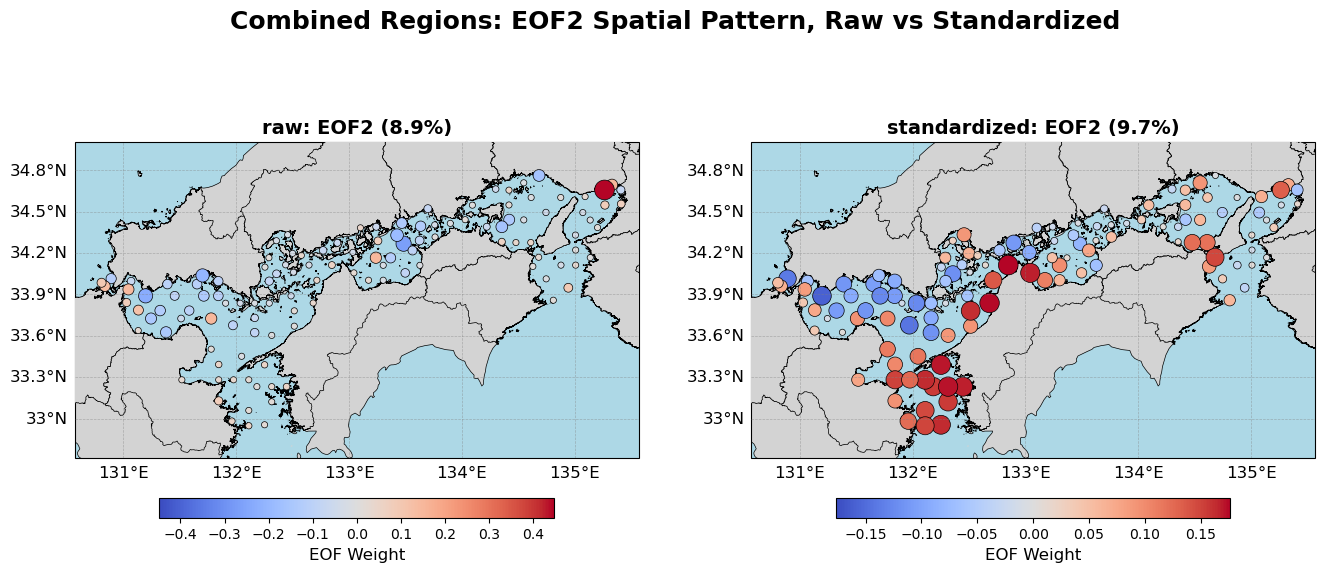

In [11]:
# --- 5e. EOF map helper (process03 styling, two panels) ---
BOUNDARY_PATHS = [
    ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Setonaikai_boundary.shp",
    ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Tokyobay_boundary.shp",
    ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Isebay_boundary.shp",
]
LAND_BOUNDARIES = []
for p in BOUNDARY_PATHS:
    if p.exists():
        g = gpd.read_file(p)
        LAND_BOUNDARIES.append(g.to_crs("EPSG:4326") if g.crs != "EPSG:4326" else g)

def plot_eof_maps_pair(results, pc, region_label, target_region, out_path):
    eof_raw = results['raw']['eofs'][f'EOF{pc}']
    coords = station_coords.loc[station_coords.index.intersection(eof_raw.index)]
    map_extent = MappingConfig.get_dynamic_extent(target_region, plot_data=coords)
    fig_w, fig_h = MappingConfig.get_dynamic_figsize(map_extent, base_width=16, is_subplot=True, n_cols=2)
    fig, axes = plt.subplots(1, 2, figsize=(fig_w, fig_h + 1), subplot_kw={'projection': ccrs.PlateCarree()})
    zoom_factor = min(max(4.5 / (map_extent[1] - map_extent[0]), 1.0), 3.0)
    for ax, mode in zip(axes, MODES):
        plot_data = coords.copy()
        plot_data['EOF'] = results[mode]['eofs'][f'EOF{pc}'].loc[coords.index]
        ax.set_facecolor(MappingConfig.COLOR_OCEAN)
        ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=MappingConfig.ZORDER_CARTOPY_LAND)
        ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black', zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)
        for lb in LAND_BOUNDARIES:
            lb.plot(ax=ax, facecolor=MappingConfig.COLOR_LAND, edgecolor=MappingConfig.COLOR_LAND_EDGE,
                    linewidth=MappingConfig.LINEWIDTH_LAND, transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_LAND)
        vmax = plot_data['EOF'].abs().max()
        sc = ax.scatter(plot_data['longitude'], plot_data['latitude'], c=plot_data['EOF'], cmap='coolwarm',
                        vmin=-vmax, vmax=vmax, s=np.maximum(plot_data['EOF'].abs() / vmax * 200 * zoom_factor, 20 * zoom_factor),
                        edgecolors='k', linewidths=0.5, transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_OBSERVATIONS)
        MappingConfig.apply_gridlines(ax)
        ax.set_extent(map_extent, crs=ccrs.PlateCarree())
        ax.set_title(f"{mode}: EOF{pc} ({results[mode]['var_pct'][f'PC{pc}']:.1f}%)")
        fig.colorbar(sc, ax=ax, orientation='horizontal', shrink=0.7, pad=0.08, label='EOF Weight')
    fig.suptitle(f'{region_label}: EOF{pc} Spatial Pattern, Raw vs Standardized', fontsize=18, fontweight='bold')
    fig.savefig(out_path, bbox_inches='tight', dpi=300)
    plt.show()

for pc in ['1', '2']:
    plot_eof_maps_pair(glob, pc, 'Combined Regions', TARGET_REGION, output_dir / f'global_eof{pc}_map_raw_vs_standardized.png')

### 5.5 Which stations drive EOF1?
The top-N stations by |EOF1| in each mode, with their interannual std. If the raw list is mostly high-std stations and the standardized list is not, raw EOF1 is an amplitude effect.

In [12]:
# --- 5f. Top-N station ranking ---
def top_stations(res, n=TOP_N):
    e = res['eofs']['EOF1']
    idx = e.abs().nlargest(n).index
    return pd.DataFrame({'EOF1': e.loc[idx].round(3), 'station_std': station_std.loc[idx].round(2)})

rank_tbl = pd.concat({m: top_stations(glob[m]).reset_index() for m in MODES}, axis=1)
display(rank_tbl)
overlap = set(top_stations(glob['raw']).index) & set(top_stations(glob['standardized']).index)
print(f"Overlap of top-{TOP_N} EOF1 stations: {len(overlap)}/{TOP_N}")
print(f"Median station std, all stations: {station_std.median():.2f} mg/L; "
      f"raw top-{TOP_N}: {top_stations(glob['raw'])['station_std'].median():.2f}; "
      f"standardized top-{TOP_N}: {top_stations(glob['standardized'])['station_std'].median():.2f}")
rank_tbl.to_csv(output_dir / 'global_top_eof1_stations.csv', index=False)

raw                    standardized                   
  zettaicode   EOF1 station_std   zettaicode   EOF1 station_std
0   00040617  0.331        1.75     00035473  0.187        0.59
1   00040620  0.315        1.61     00035486  0.173        0.49
2   00040636  0.306        1.40     00028129  0.171        0.66
3   00028153  0.249        1.31     00035459  0.169        0.41
4   00028169  0.245        1.16     00028169  0.168        1.16
5   00040632  0.221        1.27     00035542  0.158        0.69
6   00028143  0.207        1.02     00040636  0.153        1.40
7   00044594  0.190        1.36     00037179  0.150        0.97
8   00028168  0.184        0.95     00038469  0.149        0.31
9   00028150  0.176        1.01     00028168  0.148        0.95

Overlap of top-10 EOF1 stations: 3/10
Median station std, all stations: 0.66 mg/L; raw top-10: 1.29; standardized top-10: 0.68


## 6. Cross-check Against Pipeline Outputs
The notebook's results are compared with the CSVs written by `process01_calculate_pca_explained_variance_{mode}`, allowing for sign. A match confirms the notebook logic reproduces the pipeline exactly.

In [13]:
# --- 6. Cross-check with step4 process01 outputs ---
step4_dir = ProjectPaths.PROCESSED_DATA_DIR / "step4_PCA_analysis"
checks = []
for mode in MODES:
    d = step4_dir / f"process01_calculate_pca_explained_variance_{mode}"
    if not (d / 'eof_patterns.csv').exists():
        print(f"{mode}: pipeline outputs not found in {d}, skipped")
        continue
    eof_p = pd.read_csv(d / 'eof_patterns.csv', dtype={'Station_ID': str}).set_index('Station_ID')
    eof_p.index = eof_p.index.str.zfill(8)
    sc_p = pd.read_csv(d / 'pc_scores.csv', index_col=0)
    var_p = pd.read_csv(d / 'pca_variance.csv').set_index('PC')['Variance_Pct']
    for i in ['1', '2']:
        mine = glob[mode]['eofs'][f'EOF{i}'].loc[eof_p.index].values
        theirs = eof_p[f'EOF{i}'].values
        sign = np.sign(np.dot(mine, theirs))
        checks.append({
            'mode': mode, 'component': f'PC{i}',
            'eof_match': np.allclose(mine, sign * theirs, atol=1e-8),
            'score_match': np.allclose(glob[mode]['scores'][f'PC{i}'].values, sign * sc_p[f'PC{i}'].values, atol=1e-6),
            'var_notebook': glob[mode]['var_pct'][f'PC{i}'], 'var_pipeline': var_p[f'PC{i}'],
        })
display(pd.DataFrame(checks))

,mode,component,eof_match,score_match,var_notebook,var_pipeline
0,raw,PC1,True,True,15.606526,15.606526
1,raw,PC2,True,True,8.856893,8.856893
2,standardized,PC1,True,True,14.077662,14.077662
3,standardized,PC2,True,True,9.742107,9.742107


## 7. Per-Bay Comparison (as `process11`–`13`)
Divisions are expanded exactly like `step4_PCA_analysis/main.py`: `Seto Inland Sea` becomes its sub-basins, and the others are used as listed. Both modes are run on the same interpolated matrix for each division.

In [14]:
# --- 7a. Run both modes for every division ---
regions = set()
for div in DIVISIONS:
    if div == 'Seto Inland Sea':
        regions.update(merged_gdf[merged_gdf['watermass_name'] == 'Seto Inland Sea']['division'].dropna().unique())
    else:
        regions.add(div)
regions = sorted(regions)
print(f"Divisions: {regions}")

per_bay, rows = {}, []
if yearly_do_df is not None and dist_matrix_km is not None:
    for division in regions:
        mat = load_division_matrix(division)
        if mat is None:
            continue
        res_raw = run_pca(mat, 'raw')
        if len(res_raw['var_pct']) < 2:
            print(f"  {division}: fewer than 2 components, skipped")
            continue
        res_std = align_signs(res_raw, run_pca(mat, 'standardized'))
        per_bay[division] = {'raw': res_raw, 'standardized': res_std}
        rows.append({'division': division, **compare_modes(res_raw, res_std)})
        print(f"  {division}: done ({mat.shape[0]} stations)")
else:
    print("Per-bay inputs missing: section 7 skipped.")

per_bay_summary = pd.DataFrame(rows).set_index('division')
display(per_bay_summary.round(3))

Divisions: ['Aki Nada', 'Bingo Nada', 'Bisan Seto', 'Bungo Channel', 'Harima Nada', 'Hibiki Nada', 'Hiroshima Bay', 'Hiuchi Nada', 'Ise Mikawa Bay', 'Iyo Nada', 'Kii Channel', 'Osaka Bay', 'Suo Nada', 'Tokyo Bay']
  Aki Nada: done (7 stations)
  Bingo Nada: done (7 stations)
  Bisan Seto: done (9 stations)


  Bungo Channel: done (12 stations)
  Harima Nada: done (14 stations)
  Hibiki Nada: decorrelation scale file not found, skipped


  Hiroshima Bay: done (8 stations)
  Hiuchi Nada: done (9 stations)
  Ise Mikawa Bay: done (33 stations)
  Iyo Nada: done (15 stations)


  Kii Channel: done (9 stations)
  Osaka Bay: done (10 stations)


  Suo Nada: done (21 stations)
  Tokyo Bay: done (28 stations)


,n_stations,n_years,station_std_cv,PC1_var_raw,PC1_var_std,EOF1_congruence,PC1_score_r,PC2_var_raw,PC2_var_std,EOF2_congruence,PC2_score_r,EOF1_top10_overlap
division,,,,,,,,,,,,
Aki Nada,7,43,0.177,43.541,40.211,0.952,0.966,17.018,20.565,0.932,0.940,7
Bingo Nada,7,43,0.428,46.978,30.656,0.788,0.816,23.493,23.936,0.313,0.351,7
Bisan Seto,9,43,0.248,36.216,31.469,0.930,0.951,15.984,15.377,0.009,0.006,9
Bungo Channel,12,43,0.419,50.031,41.279,0.407,0.453,28.607,31.325,0.456,0.470,8
Harima Nada,14,43,0.272,46.532,38.254,0.968,0.986,11.585,14.525,0.665,0.686,10
Hiroshima Bay,8,43,0.276,40.425,29.718,0.982,0.990,16.565,23.699,0.574,0.592,8
Hiuchi Nada,9,43,0.378,29.814,27.278,0.665,0.701,21.168,17.366,0.196,0.219,9
Ise Mikawa Bay,33,43,0.311,18.894,17.975,0.506,0.520,14.919,13.186,0.227,0.252,5
Iyo Nada,15,43,0.327,38.900,35.273,0.821,0.854,19.083,20.857,0.245,0.284,6


### 7.1 Mode swap check
A low EOF1 congruence can mean two things: the standardized analysis finds a genuinely different pattern, or the same patterns appear in a different **order** (e.g. raw EOF1 ≈ standardized EOF2) because standardization changed their relative variance. The table gives, for raw EOF1 and EOF2, the best-matching standardized EOF among the first three and its |φ|.

In [15]:
# --- 7a2. Mode swap check (raw EOF1/2 vs standardized EOF1-3) ---
def best_match(res_raw, res_std, i, k=3):
    a = res_raw['eofs'][f'EOF{i}']
    phis = {j: abs(congruence(a, res_std['eofs'][f'EOF{j}'])) for j in range(1, min(k, res_std['eofs'].shape[1]) + 1)}
    j = max(phis, key=phis.get)
    return j, phis[j]

swap_rows = []
for name, res in [('Global', glob)] + list(per_bay.items()):
    row = {'division': name}
    for i in [1, 2]:
        j, phi = best_match(res['raw'], res['standardized'], i)
        row[f'raw_EOF{i}_best_std_EOF'] = j
        row[f'raw_EOF{i}_best_phi'] = phi
    swap_rows.append(row)
swap_tbl = pd.DataFrame(swap_rows).set_index('division')
display(swap_tbl.round(3))
swap_tbl.to_csv(output_dir / 'mode_swap_check.csv')

,raw_EOF1_best_std_EOF,raw_EOF1_best_phi,raw_EOF2_best_std_EOF,raw_EOF2_best_phi
division,,,,
Global,1,0.798,3,0.556
Aki Nada,1,0.952,2,0.932
Bingo Nada,1,0.788,3,0.451
Bisan Seto,1,0.930,3,0.199
Bungo Channel,2,0.734,1,0.874
Harima Nada,1,0.968,2,0.665
Hiroshima Bay,1,0.982,2,0.574
Hiuchi Nada,1,0.665,3,0.535
Ise Mikawa Bay,1,0.506,1,0.834


In [16]:
# --- 7b. Cross-check one division with process11 outputs ---
for division in ['Tokyo Bay']:
    slug = division.replace(' ', '_').lower()
    for mode in MODES:
        f = step4_dir / f"process11_calculate_pca_explained_variance_per_bay_{mode}" / slug / f"{slug}_pca_variance.csv"
        if division in per_bay and f.exists():
            v = pd.read_csv(f).set_index('PC')['Variance_Pct']
            nb = per_bay[division][mode]['var_pct']
            print(f"{division} [{mode}]: notebook PC1/PC2 = {nb['PC1']:.3f}/{nb['PC2']:.3f}%, "
                  f"pipeline = {v['PC1']:.3f}/{v['PC2']:.3f}%, match = {np.allclose(nb[['PC1','PC2']].values, v.values)}")
        else:
            print(f"{division} [{mode}]: pipeline output not available, skipped")

Tokyo Bay [raw]: notebook PC1/PC2 = 37.863/12.784%, pipeline = 37.863/12.784%, match = True
Tokyo Bay [standardized]: notebook PC1/PC2 = 23.881/20.743%, pipeline = 23.881/20.743%, match = True


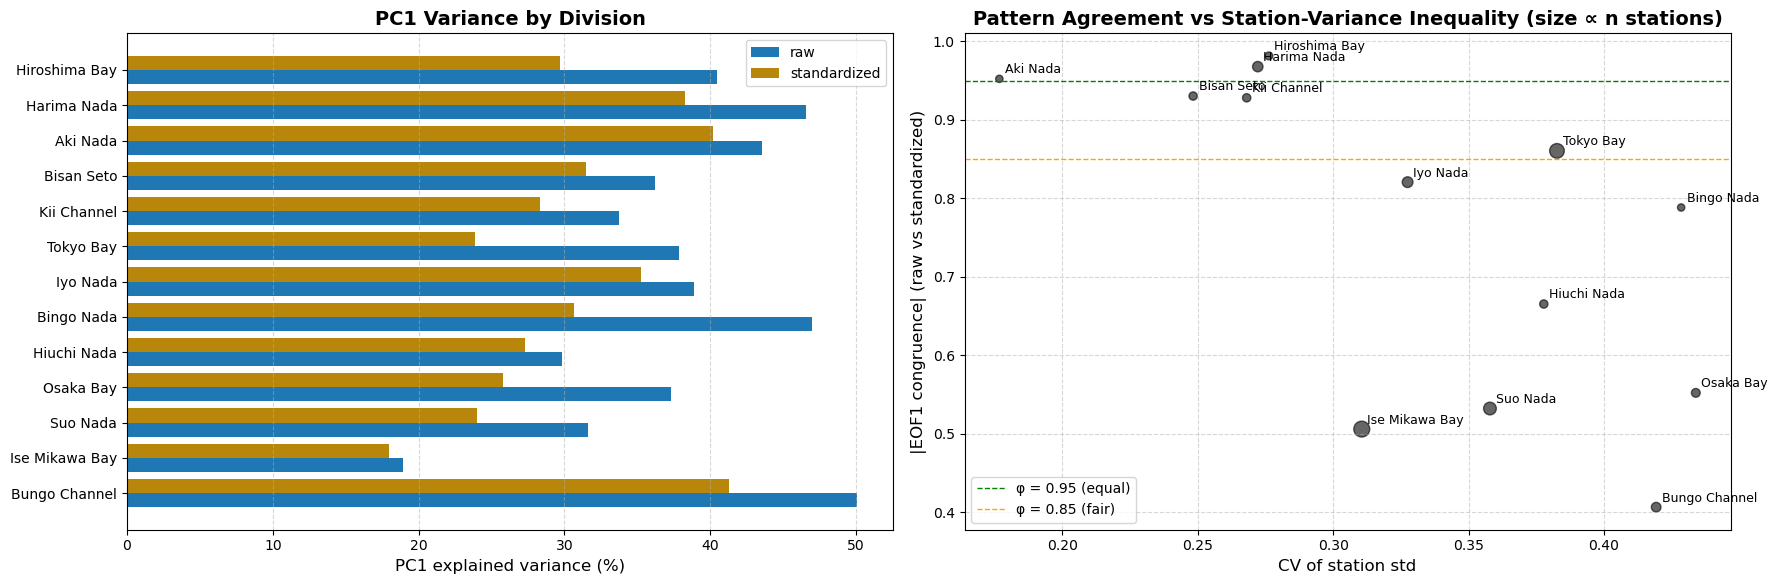

In [17]:
# --- 7c. Summary plots ---
s = per_bay_summary.sort_values('EOF1_congruence')
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

ax = axes[0]
y = np.arange(len(s))
ax.barh(y - 0.2, s['PC1_var_raw'], height=0.4, color=colors['raw'], label='raw')
ax.barh(y + 0.2, s['PC1_var_std'], height=0.4, color=colors['standardized'], label='standardized')
ax.set_yticks(y)
ax.set_yticklabels(s.index)
ax.set_xlabel('PC1 explained variance (%)')
ax.set_title('PC1 Variance by Division')
ax.legend()
ax.grid(True, axis='x', linestyle='--', alpha=0.5)

ax = axes[1]
ax.scatter(s['station_std_cv'], s['EOF1_congruence'].abs(), s=s['n_stations'] * 4, color='k', alpha=0.6)
for name, r in s.iterrows():
    ax.annotate(name, (r['station_std_cv'], abs(r['EOF1_congruence'])), fontsize=9, xytext=(4, 4), textcoords='offset points')
ax.axhline(0.95, color='green', ls='--', lw=1, label='φ = 0.95 (equal)')
ax.axhline(0.85, color='orange', ls='--', lw=1, label='φ = 0.85 (fair)')
ax.set_xlabel('CV of station std')
ax.set_ylabel('|EOF1 congruence| (raw vs standardized)')
ax.set_title('Pattern Agreement vs Station-Variance Inequality (size ∝ n stations)')
ax.legend(fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
fig.savefig(output_dir / 'per_bay_summary_raw_vs_standardized.png', bbox_inches='tight', dpi=300)
plt.show()

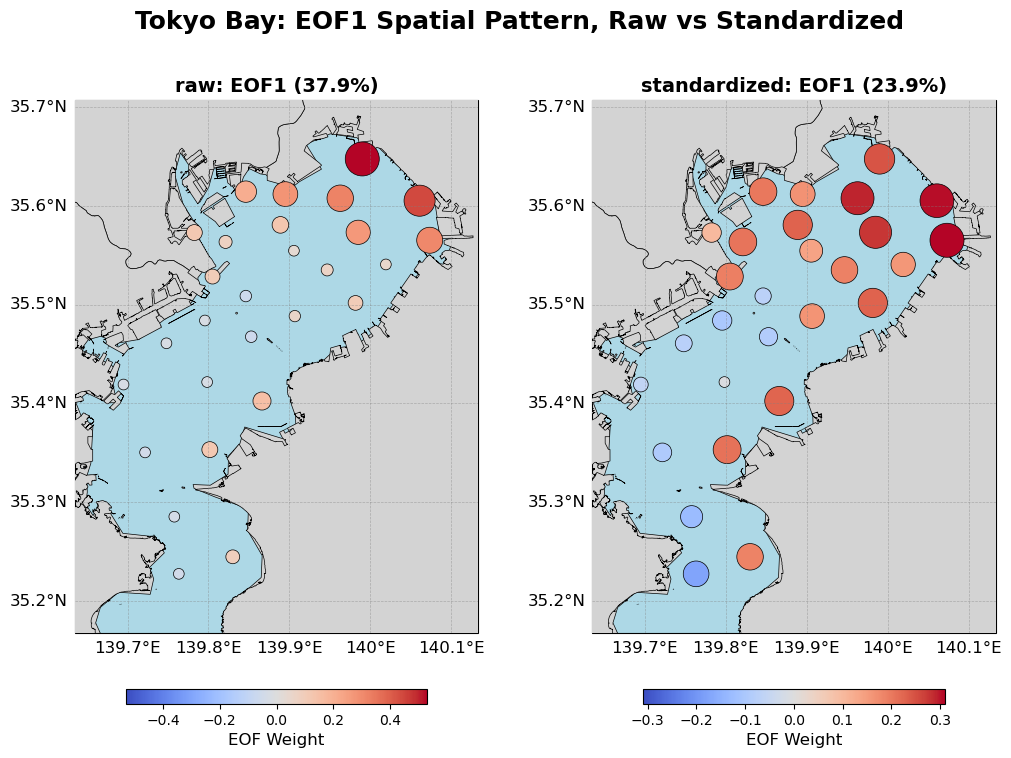

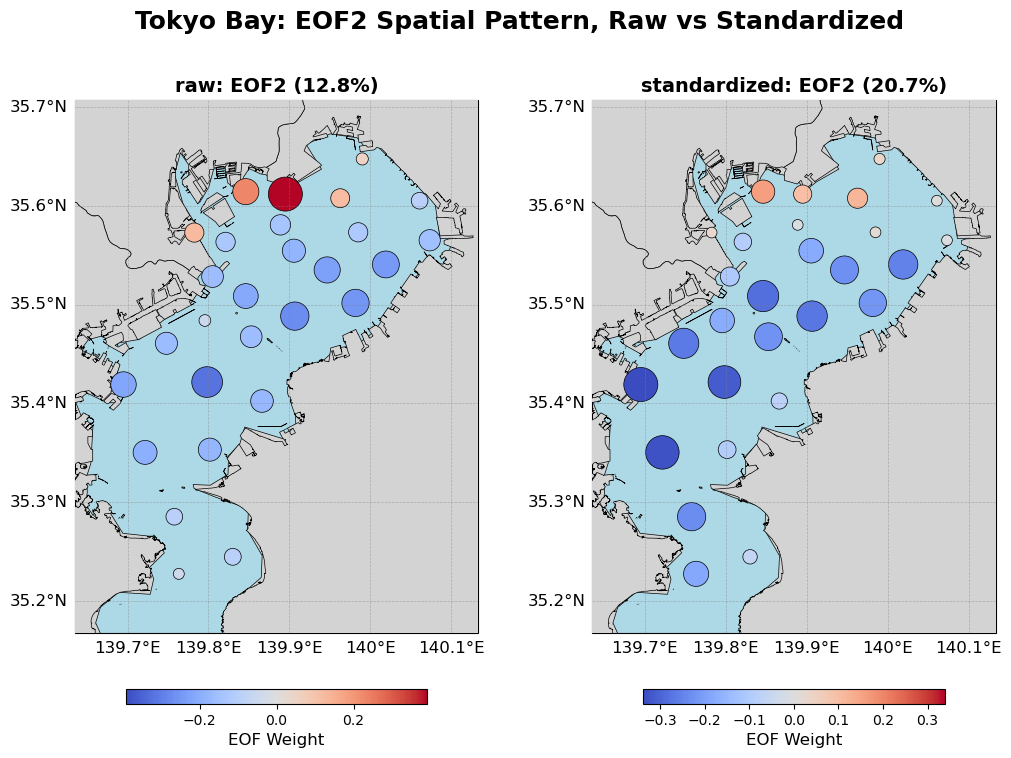

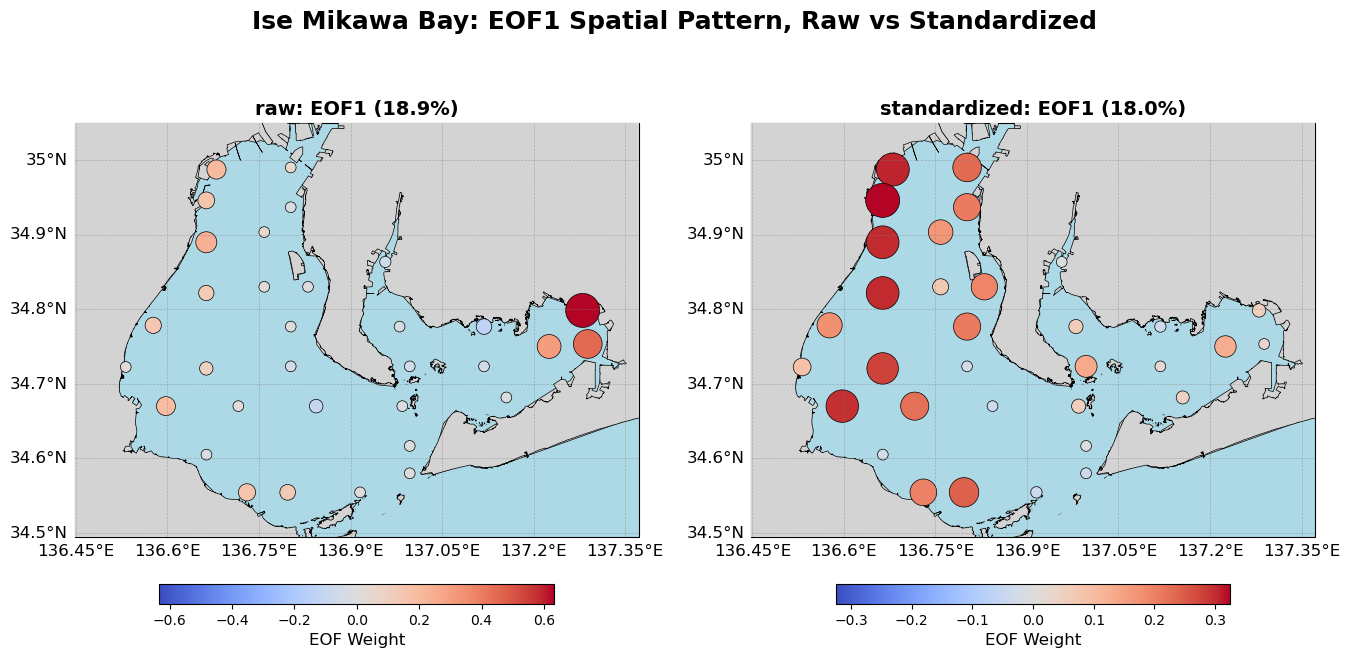

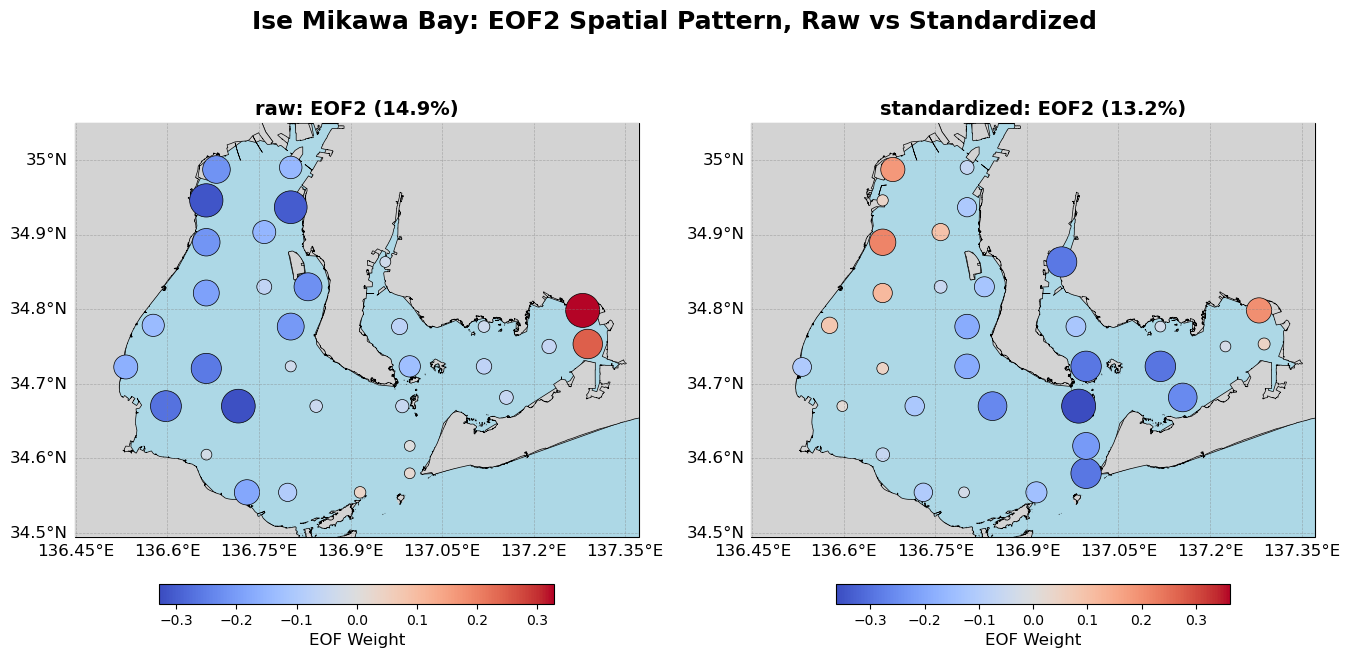

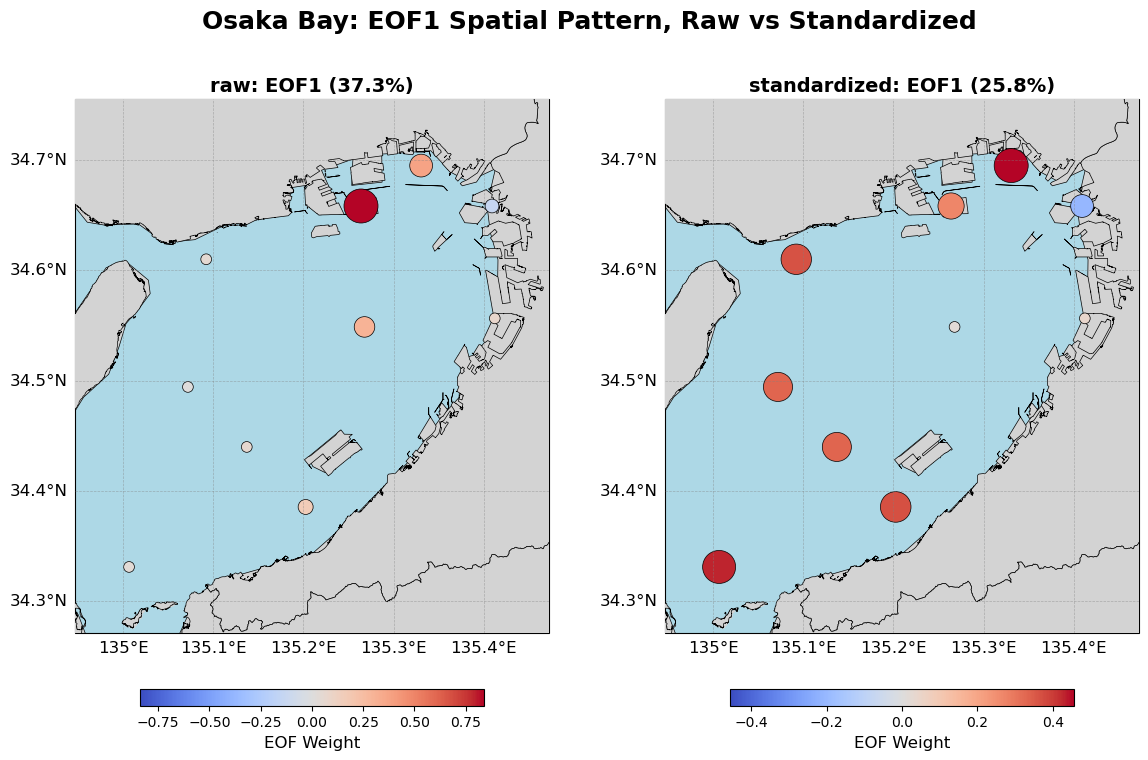

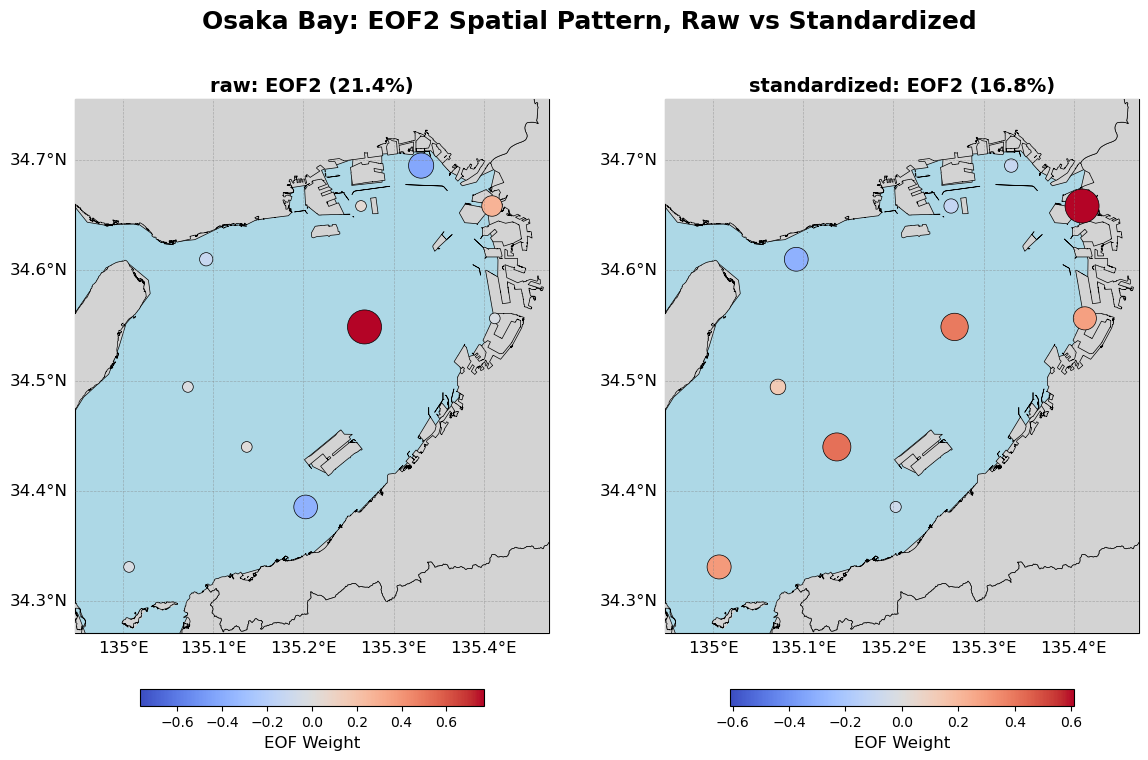

In [18]:
# --- 7d. EOF maps for the main bays ---
for division in MAP_DIVISIONS:
    if division not in per_bay:
        print(f"{division}: not computed, skipped")
        continue
    slug = division.replace(' ', '_').lower()
    for pc in ['1', '2']:
        plot_eof_maps_pair(per_bay[division], pc, division, division, output_dir / f'{slug}_eof{pc}_map_raw_vs_standardized.png')

## 8. Summary & Interpretation

*Numbers below are from the Summer / bottom run (124 stations × 41 years globally; 13 divisions; Hibiki Nada skipped because it has no decorrelation scale).*

### 8.1 The notebook reproduces the pipeline
Section 6 matches `process01_*_raw` and `process01_*_standardized` exactly (EOFs, scores and variance, up to sign). Section 7b matches `process11` for Tokyo Bay in both modes. Everything below is therefore a property of the pipeline outputs, not of this notebook.

### 8.2 Global (combined regions)
| Metric | Value |
|---|---|
| PC1 variance raw / standardized | 15.6% / 14.1% |
| EOF1 congruence φ | 0.80 (below "fair") |
| PC1 score r | 0.89 |
| EOF2 congruence / PC2 r | 0.53 / 0.59 (raw EOF2 best matches **standardized EOF3**) |
| Top-10 EOF1 station overlap | 3 / 10 |
| CV of station std | 0.45 |

- **Raw EOF1 is driven by amplitude.** The ten stations with the largest raw |EOF1| have a median interannual std of 1.29 mg/L, about twice the network median (0.66 mg/L). The standardized top ten have a median of 0.68 mg/L, which is typical. In the map, raw EOF1 is concentrated on a few high-variance stations in western Suo Nada and Osaka Bay. Standardized EOF1 is a broader, basin-wide pattern: Hiroshima Bay, Aki Nada and Iyo Nada load as strongly as Osaka Bay and Harima Nada, and the Bungo Channel has the opposite sign.
- **The PC1 time series holds up better than the pattern** (r = 0.89). The dominant interannual signal is similar in both modes, but which stations "carry" it depends on the scaling.
- **Global EOF2 does not hold up.** Do not interpret it without saying which mode was used.

### 8.3 Per division
| Agreement on EOF1 | Divisions (φ) |
|---|---|
| **Robust** (φ ≥ 0.93) | Hiroshima Bay (0.98), Harima Nada (0.97), Aki Nada (0.95), Bisan Seto (0.93), Kii Channel (0.93) |
| **Fair** (0.78–0.86) | Tokyo Bay (0.86, PC1 r = 0.91), Iyo Nada (0.82), Bingo Nada (0.79) |
| **Mode order swapped** | Bungo Channel: raw EOF1 ≈ std EOF2 (φ 0.73), raw EOF2 ≈ std EOF1 (0.87). Suo Nada: raw EOF1 ≈ std EOF2 (0.79), raw EOF2 ≈ std EOF1 (0.70) |
| **Leading mode differs** | Ise-Mikawa Bay: standardized EOF1 corresponds to raw **EOF2** (φ 0.83), and raw EOF1 has no good standardized counterpart (0.51). Osaka Bay (0.55) and Hiuchi Nada (0.67) show genuinely different patterns |

- **The divergence comes from unequal station variance.** Across divisions, the CV of station std and EOF1 congruence correlate at r = −0.67. Aki Nada (CV 0.18) agrees almost perfectly. Osaka Bay, Bingo Nada and Bungo Channel (CV ≈ 0.42–0.43) diverge most.
- **PC1 variance is always lower in standardized mode**, by 1 to 16 points. The largest drops are in Bingo Nada (47 → 31%), Tokyo Bay (38 → 24%) and Osaka Bay (37 → 26%). Here raw PC1 owes much of its share to a few high-variance stations.
- **EOF2 holds up in only three divisions:** Aki Nada (0.93), Tokyo Bay (0.85) and Kii Channel (0.83). Elsewhere it is mode-dependent: Bisan Seto φ = 0.01, Hiuchi 0.20, Ise-Mikawa 0.23, Iyo 0.25.

### 8.4 Recommendation for steps 5 and 6
1. **Keep `raw` as the primary analysis.** For hypoxia, absolute DO changes in mg/L are what matter, and the step 5/6 scripts are built on it. Report `standardized` as a robustness check.
2. **PC1 interpretations are safe** where both modes agree: Hiroshima Bay, Harima Nada, Aki Nada, Bisan Seto, Kii Channel, and with care Tokyo Bay and Iyo Nada.
3. **In Ise-Mikawa Bay, Osaka Bay, Suo Nada, Bungo Channel and Hiuchi Nada, PC1 is scaling-dependent.** Raw PC1 there mostly describes a few high-amplitude (typically hypoxic) stations. State this, and check the side-by-side maps before attributing PC1 to a basin-wide driver. For Bungo Channel and Suo Nada, compare raw EOF1 with standardized EOF2.
4. **Treat EOF2/PC2 as exploratory** in all divisions except Aki Nada, Tokyo Bay and Kii Channel.
5. **Caveat on the standardized mode:** standardizing also boosts low-variance, noisy stations to unit variance. For example, station 00038469 (std 0.31 mg/L) enters the standardized global top ten. Standardized patterns at such stations should not be over-read either.

**Outputs** (in `figures/step0_sandbox/83_raw_vs_standardized_pca_comparison/`): `raw_vs_standardized_pca_summary.csv`, `mode_swap_check.csv`, `global_top_eof1_stations.csv`, the global scree, station-std and EOF/PC comparison figures, and EOF1/EOF2 maps for the global run, Tokyo Bay, Ise-Mikawa Bay and Osaka Bay.

In [19]:
# --- 9. Save summary tables ---
summary_all = pd.concat([global_summary.to_frame().T, per_bay_summary])
summary_all.index.name = 'division'
summary_all.to_csv(output_dir / 'raw_vs_standardized_pca_summary.csv')
display(summary_all.round(3))
print(f"Saved: {output_dir / 'raw_vs_standardized_pca_summary.csv'}")

,n_stations,n_years,station_std_cv,PC1_var_raw,PC1_var_std,EOF1_congruence,PC1_score_r,PC2_var_raw,PC2_var_std,EOF2_congruence,PC2_score_r,EOF1_top10_overlap
division,,,,,,,,,,,,
Global,124.0,41.0,0.446,15.607,14.078,0.798,0.888,8.857,9.742,0.527,0.594,3.0
Aki Nada,7.0,43.0,0.177,43.541,40.211,0.952,0.966,17.018,20.565,0.932,0.940,7.0
Bingo Nada,7.0,43.0,0.428,46.978,30.656,0.788,0.816,23.493,23.936,0.313,0.351,7.0
Bisan Seto,9.0,43.0,0.248,36.216,31.469,0.930,0.951,15.984,15.377,0.009,0.006,9.0
Bungo Channel,12.0,43.0,0.419,50.031,41.279,0.407,0.453,28.607,31.325,0.456,0.470,8.0
Harima Nada,14.0,43.0,0.272,46.532,38.254,0.968,0.986,11.585,14.525,0.665,0.686,10.0
Hiroshima Bay,8.0,43.0,0.276,40.425,29.718,0.982,0.990,16.565,23.699,0.574,0.592,8.0
Hiuchi Nada,9.0,43.0,0.378,29.814,27.278,0.665,0.701,21.168,17.366,0.196,0.219,9.0
Ise Mikawa Bay,33.0,43.0,0.311,18.894,17.975,0.506,0.520,14.919,13.186,0.227,0.252,5.0


Saved: /home/reyha/SIS_Analysis_WSL/figures/step0_sandbox/83_raw_vs_standardized_pca_comparison/raw_vs_standardized_pca_summary.csv
